In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "dotted",
    "FLSQR-I": "dotted",
    "FLSQR-R": "dashed",
    "FLSQR-W": "dashdot",
    "IRW-FLSQR": (0, (3, 1, 1, 1, 1, 1)),
}


from trips.utilities.weights import smoothed_holder_weights


# from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
# from pgkbsolver import MMGKB, IASGKB, MM2019GKB
# from f2019solver import MM2019FGK2019, IASFGK2019


from msolver import VanillaGKS

from msolver import MMGKS

from pgkbsolver import MMGKB

from fsolver import MMFGK

from f2019solver import MMFGK2019

from fIRWsolver import MMFGKIRW


# What methods to do this for?
# S-GKS
# PS-GKS
# PS-GKB
# FGK
# IRW-FLSQR
# FLSQR-I
# FLSQR-R

# Setup problem data

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)
ground_truth -= 5.5
ground_truth *= -1

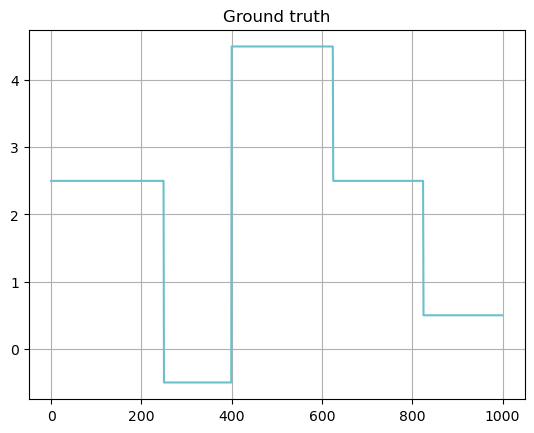

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


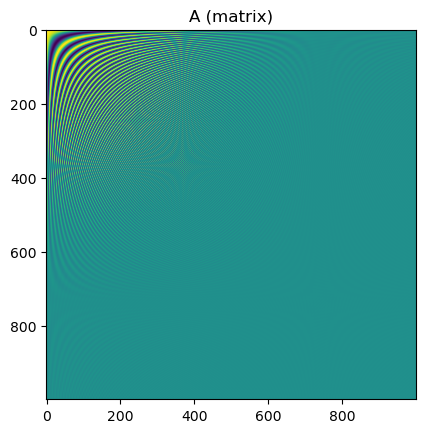

In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [6]:
# Only first 50 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [7]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

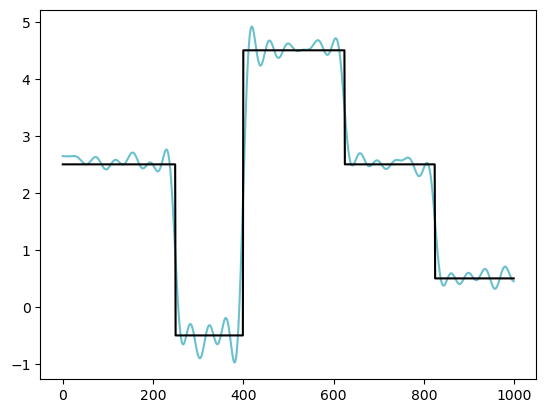

In [8]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [10]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

fgk_breakdown_tol = 1e-25

In [19]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))


epsilon = 1e-3
mm_weight_params = {
    "epsilon": epsilon,
    "q": 1.0,
}



all_data = []
noise_level_sigmas = [0.001, 0.005, 0.001, 0.005, 0.01, 0.05, 0.1]
for noise_level_sigma in noise_level_sigmas:


    # Generate synthetic data
    np.random.seed(0)
    A = P @ F
    b_true = A @ ground_truth
    noise_vec = np.random.normal(size=A.shape[0])
    noise_vec /= np.linalg.norm(noise_vec)
    noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
    #noise_sigma = 0.01*np.amax(b_true)
    #noise_var = noise_sigma**2
    noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
    b = b_true + noise_vec
    #b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

    # Vanilla GKS
    v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                        regparam_kwargs={"eta":1.01},  xker=xker)



    mm_gks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


    # S-GKS
    mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
    
    # PS-GKS
    mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
    
    # PS-GKB
    mm_psgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    mm_psgkb_data = mm_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )
    
    # FGK
    mm_fgk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
    mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )


    # IRW-FLSQR
    mm_fgkirw_solver = MMFGKIRW(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Option IRW

    mm_fgkIRW_data = mm_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                    #  regparam_kwargs={"eta":1.01},
                                                    lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                    #  init_dim=5
                                                    )


    # FLSQR-I, R, and W
    mm_fgk2019_solver = MMFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Options I, R, W

    mm_fgk2019I_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-R
    mm_fgk2019R_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-W
    mm_fgk2019W_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    all_data.append( (noise_level_sigma, mm_sgks_data, mm_psgks_data, mm_psgkb_data, mm_fgk_data, mm_fgkIRW_data, mm_fgk2019I_data, mm_fgk2019R_data, mm_fgk2019W_data)  ) 





20997.145859858687
2927.028698116259
3997.7152797078443
3139.574250948759
9535.41102985612
3578.6164060986102
4141.138793402559
4088.954892033023
4101.219092832852
4106.440836670578
4121.285542412504
4116.28064921643
4116.2610033898
4117.876104945381
4122.386798236027
4122.003406238372
4119.509995842868
4120.986127395793
4123.001060582401
4124.749203306297
4124.361669518418
4121.884322700444
4123.944300127402
4124.132336566711
4123.964146428665
4123.1079464848
4122.660712678097
4123.965241856983
4123.658294283195
4123.201182094755
4123.492610490797
4123.581045297693
4123.682709371666
4123.54413139421
4123.4189952774
4123.605407937156
4123.630379279469
4123.535005629013
4123.481976571228
4123.517339581767
4123.523952723621
4123.6395487610735
4123.518481380972
4123.5179452657585
4123.600392340433
4123.541826442599
4123.546053855261
4123.537638082766
4123.548896087455
4123.556638602305
4123.554759260272
4123.55004947992
4123.548794797515
4123.550013768381
4123.554453149819
4123.5489354685

962.8694469562016
1223.964688264232
989.1788680281369
458.2308916548995
1092.5373020576028
1042.8999504185622
896.2280038586962
729.2152422458618
797.1536896793875
897.9989492757924
916.9574487192555
645.0448935600068
847.8745234166238
908.4103694136082
727.6768547104431
875.8566901000314
816.07187699659
779.5118176566078
715.8362469857301
829.6719255335511
857.7288884189691
893.797284244716
855.5237250429259
769.498522953545
805.0325678887244
891.4038288247468
894.8604200359036
913.4002138628582
962.5011007924934
899.3321069143705
837.7586230051108
906.2992732868922
1067.2128699372224
1158.4599378612234
1219.4018083126793
1217.618136555917
994.7803480812963
810.5418117544125
1065.7970415132108
1183.6535785137642
1141.6359468676944
978.4337357513114
928.215760121966
984.1180397225079
924.0228876553447
857.124562901948
951.4174762017378
1102.9562899352327
1113.697203247977
837.0887358260384
703.127640686331
1011.2307111459869
1040.3399951098713
689.2222061963024
832.01577695578
871.9025

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:888: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
211.87570725271038
259.4255386955153
265.39400967603706
241.28322964177548
217.77834931604903
235.35074053881775
241.5801887010188
263.82596626548485
274.62246010621203
277.4931227779649
290.88643675821316
315.1038858923776
324.9048446000003
332.6423949473148
332.54888011369025
333.4116577356147
338.5639369101032
344.6449077565777
354.4471328393521
363.11057269953943
371.9873129057307
379.84541694946984
385.92437026964404
393.19319060985697
401.12575348441266
409.6019937497272
417.1786015513466
424.6287525826967
432.0425077576221
439.7253391253598
446.675039249241
453.91634208935074
461.0882366163967
468.0900977972398
474.8750066816322
481.5140578378211
488.0825173300372
494.49716668864215
500.6540114927627
506.73876384083945
512.6177995865671
518.3578206909859
523.9452091112764
529.3718474867345
534.6427523007322
539.7913401875194
544.7840707499366
549.641846106043
554.3655225034043
558.9596104222485
563.4264852684591
5

...

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1.9009294444328644
Starting iteration 7
3.5993485312017
Starting iteration 8
3.2757948068631904
Starting iteration 9
3.2406953164258754
Starting iteration 10
3.9199847157316414
Starting iteration 11
4.178959724732671
Starting iteration 12
4.134221307900369
Starting iteration 13
4.213318216346577
Starting iteration 14
4.305813965966078
Starting iteration 15
4.336447450324697
Starting iteration 16
4.675839486730197
Starting iteration 17
4.656888869961213
Starting iteration 18
4.669228677717414
Starting iteration 19
4.710249386853342
Starting iteration 20
4.713683928621778
Starting iteration 21
5.114786705020583
Starting iteration 22
5.110447327139043
Starting iteration 23
5.517355749661052
Starting iteration 24
5.306122388814388
Starting iteration 25
5.1782745715323895
Starting iteration 26
5.005859051593813

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
2.2509972028416523
Starting iteration 7
8.17623551831854
Starting iteration 8
10.577799600137874
Starting iteration 9
11.25047324110863
Starting iteration 10
11.56308101810427
Starting iteration 11
11.654114824735917
Starting iteration 12
11.720678006223775
Starting iteration 13
11.6856558888332
Starting iteration 14
11.878218259327664
Starting iteration 15
11.856865864038115
Starting iteration 16
12.000413736973346
Starting iteration 17
11.992369383210715
Starting iteration 18
12.131057556521807
Starting iteration 19
12.209451710347247
Starting iteration 20
12.381500998083373
Starting iteration 21
12.546898884625339
Starting iteration 22
12.609939629962614
Starting iteration 23
12.775393294914206
Starting iteration 24
13.027823064461503
Starting iteration 25
13.419482536439249
Starting iteration 26
13.674

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
0.819228538218888
Starting iteration 7
1.3785000399449778
Starting iteration 8
1.7630025198624835
Starting iteration 9
1.8236767147396107
Starting iteration 10
1.4265376809817758
Starting iteration 11
1.4307784879226206
Starting iteration 12
1.3296911932045563
Starting iteration 13
1.3165403240909794
Starting iteration 14
1.2833248252504426
Starting iteration 15
1.2700631883365705
Starting iteration 16
1.2680838663243845
Starting iteration 17
1.244709589823889
Starting iteration 18
1.254220113710604
Starting iteration 19
1.2809642066771987
Starting iteration 20
1.3045743759069528
Starting iteration 21
1.3013686326973009
Starting iteration 22
1.299928342178539
Starting iteration 23
1.3009018262149465
Starting iteration 24
1.3030508552850448
Starting iteration 25
1.3039353830013936
Starting iteration 26
1.29

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
51.174690665051145
Starting iteration 7
82.3986719881046
Starting iteration 8
92.91074002822886
Starting iteration 9
97.73226139289831
Starting iteration 10
101.5786956056945
Starting iteration 11
103.20729587358912
Starting iteration 12
103.07782126429153
Starting iteration 13
103.91596679324526
Starting iteration 14
104.01644579226695
Starting iteration 15
104.13997147303483
Starting iteration 16
104.50304468859196
Starting iteration 17
104.42179080664785
Starting iteration 18
104.42508448317186
Starting iteration 19
104.77831411538399
Starting iteration 20
105.28794742076693
Starting iteration 21
105.4116826815217
Starting iteration 22
105.40636805644341
Starting iteration 23
105.4019669367823
Starting iteration 24
105.74426051912069
Starting iteration 25
105.71766488827278
Starting iteration 26
105.783

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
2.172182175608491
Starting iteration 7
7.794797468379474
Starting iteration 8
9.517920059614813
Starting iteration 9
10.024751302286063
Starting iteration 10
9.952050624612292
Starting iteration 11
9.40713254550848
Starting iteration 12
9.250930342247056
Starting iteration 13
9.139239778264255
Starting iteration 14
9.08309994361038
Starting iteration 15
9.007842716702177
Starting iteration 16
9.05998617721869
Starting iteration 17
9.070714610351713
Starting iteration 18
9.079067548176761
Starting iteration 19
9.33389990028441
Starting iteration 20
9.391556966417458
Starting iteration 21
9.41776592778795
Starting iteration 22
9.489500150773337
Starting iteration 23
9.411336703140902
Starting iteration 24
9.64505138037731
Starting iteration 25
9.750845504933313
Starting iteration 26
9.890735933963537
Startin

In [20]:
noise_level_sigmas

[0.001, 0.005, 0.001, 0.005, 0.01, 0.05, 0.1]

In [22]:
sgks_rres = []
psgks_rres = []
psgkb_rres = []
psfgk_rres = []
fgkirw_rres = []
flsqrI_rres = []
flsqrR_rres = []
flsqrW_rres = []

sgks_gini = []
psgks_gini = []
psgkb_gini = []
psfgk_gini = []
fgkirw_gini = []
flsqrI_gini = []
flsqrR_gini = []
flsqrW_gini = []


for item in all_data:
    
    noise_sigma, sgks_data, psgks_data, psgkb_data, psfgk_data, fgkirw_data, flsqrI_data, flsqrR_data, flsqrW_data = item
    
    sgks_rres.append(sgks_data["rre_history"][-1])
    psgks_rres.append(psgks_data["rre_history"][-1])
    psgkb_rres.append(psgkb_data["rre_history"][-1])
    psfgk_rres.append(psfgk_data["rre_history"][-1])

    fgkirw_rres.append(fgkirw_data["rre_history"][-1])
    flsqrI_rres.append(flsqrI_data["rre_history"][-1])
    flsqrR_rres.append(flsqrR_data["rre_history"][-1])
    flsqrW_rres.append(flsqrW_data["rre_history"][-1])

    metric = "gini_indices"
    sgks_gini.append(sgks_data[metric][-1])
    psgks_gini.append(psgks_data[metric][-1])
    psgkb_gini.append(psgkb_data[metric][-1])
    psfgk_gini.append(psfgk_data[metric][-1])

    fgkirw_gini.append(fgkirw_data[metric][-1])
    flsqrI_gini.append(flsqrI_data[metric][-1])
    flsqrR_gini.append(flsqrR_data[metric][-1])
    flsqrW_gini.append(flsqrW_data[metric][-1])




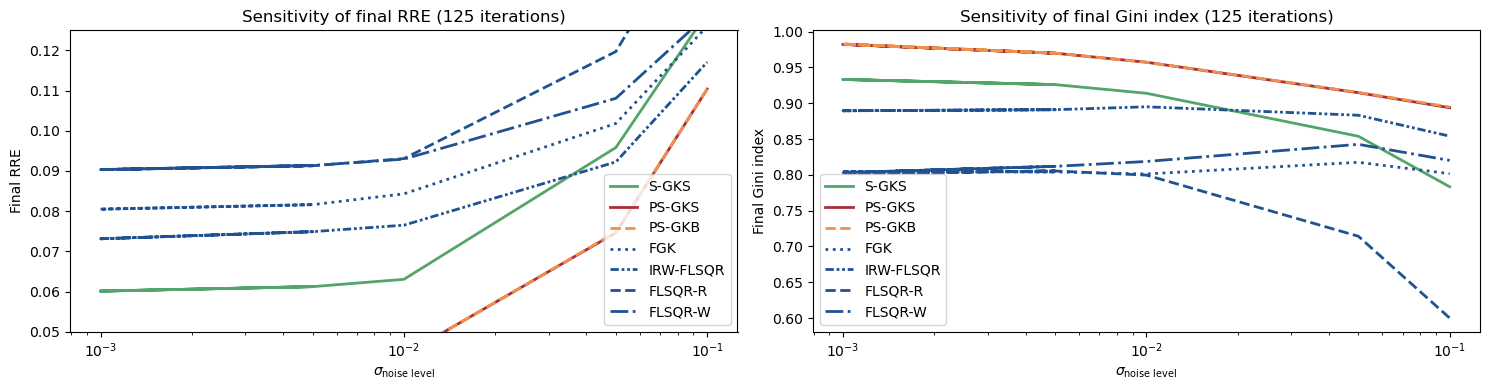

In [27]:
lw = 2.0
marker_size = 10.0

fig, axs = plt.subplots(1,2,figsize=(15,4))


axs[0].plot(noise_level_sigmas, sgks_rres, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"], lw=lw)
#axs[0].scatter(epsilons, sgks_rres, color=method_colors["S-GKS"], marker=method_markers["S-GKS"], s=marker_size)

axs[0].plot(noise_level_sigmas, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"], ls=method_lines["PS-GKS"], lw=lw)
#axs[0].scatter(epsilons, psgks_rres, color=method_colors["PS-GKS"], marker=method_markers["PS-GKS"], s=marker_size)

axs[0].plot(noise_level_sigmas, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"], ls="dashed",  lw=lw)
#axs[0].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[0].plot(noise_level_sigmas, psfgk_rres, label="FGK", color=method_colors["FGK"], lw=lw, ls="dotted")
#axs[0].scatter(epsilons, psgkb_rres, color=method_colors["FGK"], marker=method_markers["FGK"], s=marker_size)

axs[0].plot(noise_level_sigmas, fgkirw_rres, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"], ls=method_lines["IRW-FLSQR"], lw=lw)
#axs[0].scatter(epsilons, fgkirw_rres, color=method_colors["IRW-FLSQR"], marker=method_markers["IRW-FLSQR"], s=marker_size)

#axs[0].plot(epsilons, flsqrI_rres, label="FLSQR-I", color=method_colors["FLSQR-I"], ls=method_lines["FLSQR-I"], lw=lw)
#axs[0].scatter(epsilons, flsqrI_rres, color=method_colors["FLSQR-I"], marker=method_markers["FLSQR-I"], s=marker_size)

axs[0].plot(noise_level_sigmas, flsqrR_rres, label="FLSQR-R", color=method_colors["FLSQR-R"], ls=method_lines["FLSQR-R"], lw=lw)
#axs[0].scatter(epsilons, flsqrR_rres, color=method_colors["FLSQR-R"], marker=method_markers["FLSQR-R"], s=marker_size)

axs[0].plot(noise_level_sigmas, flsqrW_rres, label="FLSQR-W", color=method_colors["FLSQR-W"], ls=method_lines["FLSQR-W"], lw=lw)
#axs[0].scatter(epsilons, flsqrW_rres, color=method_colors["FLSQR-W"], marker=method_markers["FLSQR-W"], s=marker_size)
# plt.semilogx(epsilons, psfgk_rres, label="FGK")

axs[0].set_xscale("log")
axs[0].set_xlabel("$\sigma_{\\text{noise level}}$")
axs[0].set_title("Sensitivity of final RRE (125 iterations)")
axs[0].set_ylabel("Final RRE")
axs[0].legend()









metric = "gini_indices"
axs[1].plot(noise_level_sigmas, sgks_gini, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"], lw=lw)
#axs[0].scatter(epsilons, sgks_rres, color=method_colors["S-GKS"], marker=method_markers["S-GKS"], s=marker_size)

axs[1].plot(noise_level_sigmas, psgks_gini, label="PS-GKS", color=method_colors["PS-GKS"], ls=method_lines["PS-GKS"], lw=lw)
#axs[0].scatter(epsilons, psgks_rres, color=method_colors["PS-GKS"], marker=method_markers["PS-GKS"], s=marker_size)

axs[1].plot(noise_level_sigmas, psgkb_gini, label="PS-GKB", color=method_colors["PS-GKB"], ls="dashed",  lw=lw)
#axs[1].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[1].plot(noise_level_sigmas, psfgk_gini, label="FGK", color=method_colors["FGK"], lw=lw, ls="dotted")
#axs[1].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[1].plot(noise_level_sigmas, fgkirw_gini, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"], ls=method_lines["IRW-FLSQR"], lw=lw)
#axs[0].scatter(epsilons, fgkirw_rres, color=method_colors["IRW-FLSQR"], marker=method_markers["IRW-FLSQR"], s=marker_size)

#axs[1].plot(epsilons, flsqrI_gini, label="FLSQR-I", color=method_colors["FLSQR-I"], ls=method_lines["FLSQR-I"], lw=lw)
#axs[0].scatter(epsilons, flsqrI_rres, color=method_colors["FLSQR-I"], marker=method_markers["FLSQR-I"], s=marker_size)

axs[1].plot(noise_level_sigmas, flsqrR_gini, label="FLSQR-R", color=method_colors["FLSQR-R"], ls=method_lines["FLSQR-R"], lw=lw)
#axs[0].scatter(epsilons, flsqrR_rres, color=method_colors["FLSQR-R"], marker=method_markers["FLSQR-R"], s=marker_size)

axs[1].plot(noise_level_sigmas, flsqrW_gini, label="FLSQR-W", color=method_colors["FLSQR-W"], ls=method_lines["FLSQR-W"], lw=lw)
#axs[0].scatter(epsilons, flsqrW_rres, color=method_colors["FLSQR-W"], marker=method_markers["FLSQR-W"], s=marker_size)
# plt.semilogx(epsilons, psfgk_rres, label="FGK")

axs[1].set_xscale("log")
axs[1].set_xlabel("$\sigma_{\\text{noise level}}$")
axs[1].set_title("Sensitivity of final Gini index (125 iterations)")
axs[1].set_ylabel("Final Gini index")
axs[1].legend()


axs[0].set_ylim(0.05, 0.125)
axs[0].set_xscale("log")
axs[1].set_xscale("log")


fig.tight_layout()
fig.savefig("1d_cosine_mm_noise_sensitivity.png", dpi=250, bbox_inches="tight")
fig.savefig("1d_cosine_mm_noise_sensitivity.eps", format="eps", dpi=250, bbox_inches="tight")

# Again but for IAS?

In [28]:

from msolver import VanillaGKS

from msolver import IASGKS

from pgkbsolver import IASGKB

from fsolver import IASFGK

from f2019solver import IASFGK2019

from fIRWsolver import IASFGKIRW

In [30]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))


ias_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}



all_data = []
noise_level_sigmas = [0.001, 0.005, 0.001, 0.005, 0.01, 0.05, 0.1]
for noise_level_sigma in noise_level_sigmas:


    # Generate synthetic data
    np.random.seed(0)
    A = P @ F
    b_true = A @ ground_truth
    noise_vec = np.random.normal(size=A.shape[0])
    noise_vec /= np.linalg.norm(noise_vec)
    noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
    #noise_sigma = 0.01*np.amax(b_true)
    #noise_var = noise_sigma**2
    noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
    b = b_true + noise_vec
    #b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

    # Vanilla GKS
    v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                        regparam_kwargs={"eta":1.01},  xker=xker)



    ias_gks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


    # S-GKS
    ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
    
    # PS-GKS
    ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
    
    # PS-GKB
    ias_psgkb_solver = IASGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    ias_psgkb_data = ias_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )
    
    # FGK
    ias_fgk_solver = IASFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
    ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )


    # IRW-FLSQR
    ias_fgkirw_solver = IASFGKIRW(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Option IRW

    ias_fgkIRW_data = ias_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                    #  regparam_kwargs={"eta":1.01},
                                                    lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                    #  init_dim=5
                                                    )


    # FLSQR-I, R, and W
    ias_fgk2019_solver = IASFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Options I, R, W

    ias_fgk2019I_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-R
    ias_fgk2019R_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-W
    ias_fgk2019W_data = ias_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=ias_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    all_data.append( (noise_level_sigma, ias_sgks_data, ias_psgks_data, ias_psgkb_data, ias_fgk_data, ias_fgkIRW_data, ias_fgk2019I_data, ias_fgk2019R_data, ias_fgk2019W_data)  ) 





20997.145859858687
2927.028698116259
3997.7152797078443
3139.574250948759
9535.41102985612
3578.6164060986102
4141.138793402559
4088.954892033023
4101.219092832852
4106.440836670578
4121.285542412504
4116.28064921643
4116.2610033898
4117.876104945381
4122.386798236027
4122.003406238372
4119.509995842868
4120.986127395793
4123.001060582401
4124.749203306297
4124.361669518418
4121.884322700444
4123.944300127402
4124.132336566711
4123.964146428665
4123.1079464848
4122.660712678097
4123.965241856983
4123.658294283195
4123.201182094755
4123.492610490797
4123.581045297693
4123.682709371666
4123.54413139421
4123.4189952774
4123.605407937156
4123.630379279469
4123.535005629013
4123.481976571228
4123.517339581767
4123.523952723621
4123.6395487610735
4123.518481380972
4123.5179452657585
4123.600392340433
4123.541826442599
4123.546053855261
4123.537638082766
4123.548896087455
4123.556638602305
4123.554759260272
4123.55004947992
4123.548794797515
4123.550013768381
4123.554453149819
4123.5489354685

1682.960587414658
8321.629132630525
7143.221149340576
3781.259192494932
12687.646678410945
24680.271605092177
31641.66378243798
33010.088145812355
21819.16014997418
11686.450586296916
12018.849046039391
17884.533574931545
22701.433268096982
25769.99794312435
28641.848849555645
31113.47903497873
32525.71424506493
32689.827621422985
31483.876194185345
29646.63101846761
28394.056257954355
27227.26706989073
26028.65922467555
26730.898932198714
29415.875517822744
32070.48169770115
35029.02287499521
41400.537437115396
51837.1110963119
66822.90097526234
75313.41167154208
82217.34597928947
81193.82883112729
67775.62192377425
54108.702269326444
56114.05982866826
70031.53736146093
78365.22857270307
80955.72952366796
80780.64471920539
73496.24900348463
61833.35233189888
53943.702964249074
43311.99171129276
49381.15679782817
58078.70884291244
62963.549935200674
64456.91862578384
66788.41110022922
75099.48956562509
77508.91492282655
67919.0549547934
58297.45903402567
63037.394000818516
76917.537858

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:888: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
951.33860143635
1e-07
1233.8529903171207
1e-07
1344.2602789010837
11162.706681950836
1e-07
1344.754872127439
12132.354421637807
15671.378395568849
39579.70438443891
82711.10372434225
111940.69605183102
224934.66302951306
813060.1518952018
10000000.0
10000000.0
1e-07
900.9679230747937
10066.75481659734
55579.70684197214
255849.75756971643
1223204.4119678715
10000000.0
10000000.0
1e-07
646.6353544414304
7772.2295491474215
41783.526209225965
148407.65615926107
327556.2255815029
727177.7415611577
1659206.4649385628
3938224.2883020253
7442521.510360633
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
10000000.0
100000

...

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
36.94290131606999
Starting iteration 9
51.58771216903518
Starting iteration 10
56.272935888833366
Starting iteration 11
57.59584890886336
Starting iteration 12
58.11348315385707
Starting iteration 13
58.405673284220356
Starting iteration 14
58.45405287919983
Starting iteration 15
58.4936420326268
Starting iteration 16
58.52069609480246
Starting iteration 17
58.527863130411276
Starting iteration 18
58.532971391549765
Starting iteration 19
58.54216206484904
Starting iteration 20
58.56721285719969
Starting iteration 21
58.582595361728295
Starting iteration 22
58.59220288252215
Starting iteration 23
58.62177435842443
Starting iteration 24
58.64690477153992
Starting iteration 25
58.68325959244962
Starting iteration 26
58.7119894620532
Starting iteration 27
5

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
36.901653281386636
Starting iteration 9
51.69418852388222
Starting iteration 10
56.63874977141636
Starting iteration 11
58.064030937638584
Starting iteration 12
58.603584964984925
Starting iteration 13
58.89102643919518
Starting iteration 14
58.93043091664015
Starting iteration 15
58.96894321651517
Starting iteration 16
58.98514490381345
Starting iteration 17
58.98841227705005
Starting iteration 18
58.98943330073313
Starting iteration 19
58.99172621116276
Starting iteration 20
59.00793334538408
Starting iteration 21
59.020975203146946
Starting iteration 22
59.03017914791587
Starting iteration 23
59.05200945484381
Starting iteration 24
59.07776114929327
Starting iteration 25
59.095609452904874
Starting iteration 26
59.1374748460236
Starting iteration 27


Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
37.02426075813081
Starting iteration 9
43.637421342207155
Starting iteration 10
45.27904743564004
Starting iteration 11
45.70613438442305
Starting iteration 12
45.875086476522
Starting iteration 13
45.94988540865802
Starting iteration 14
45.94350649401757
Starting iteration 15
45.94851947276122
Starting iteration 16
45.94879688166838
Starting iteration 17
45.94883060293654
Starting iteration 18
45.94893540451946
Starting iteration 19
45.94944969553509
Starting iteration 20
45.94984274700809
Starting iteration 21
45.949891528040155
Starting iteration 22
45.94987118526628
Starting iteration 23
45.949795304886116
Starting iteration 24
45.94966951358641
Starting iteration 25
45.949935106035234
Starting iteration 26
45.94892097034282
Starting iteration 27
45

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
92.27327407190151
Starting iteration 9
108.31762525690581
Starting iteration 10
112.54427855189608
Starting iteration 11
113.59015697223789
Starting iteration 12
113.87966003090285
Starting iteration 13
113.9924836033241
Starting iteration 14
114.01168959249158
Starting iteration 15
114.01675767180025
Starting iteration 16
114.01764892841331
Starting iteration 17
114.0176903803923
Starting iteration 18
114.01768983589655
Starting iteration 19
114.0177176515969
Starting iteration 20
114.01772936710734
Starting iteration 21
114.01773142413435
Starting iteration 22
114.01773163003091
Starting iteration 23
114.01773462165953
Starting iteration 24
114.017767083354
Starting iteration 25
114.01781505926046
Starting iteration 26
114.01781535728696
Starting iter

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
36.90930965144934
Starting iteration 9
51.6658140222741
Starting iteration 10
56.58634641799519
Starting iteration 11
57.98297511388676
Starting iteration 12
58.50325590458656
Starting iteration 13
58.777476093871236
Starting iteration 14
58.8210736849121
Starting iteration 15
58.85493623648506
Starting iteration 16
58.8683082492997
Starting iteration 17
58.871195029130924
Starting iteration 18
58.872025191014146
Starting iteration 19
58.87574792883289
Starting iteration 20
58.897913427237235
Starting iteration 21
58.90745153730206
Starting iteration 22
58.91072157410191
Starting iteration 23
58.92429264382744
Starting iteration 24
58.929857510644716
Starting iteration 25
58.93550864259402
Starting iteration 26
58.99686046313451
Starting iteration 27
59

In [ ]:
sgks_rres = []
psgks_rres = []
psgkb_rres = []
psfgk_rres = []
fgkirw_rres = []
flsqrI_rres = []
flsqrR_rres = []
flsqrW_rres = []

sgks_gini = []
psgks_gini = []
psgkb_gini = []
psfgk_gini = []
fgkirw_gini = []
flsqrI_gini = []
flsqrR_gini = []
flsqrW_gini = []


for item in all_data:
    
    noise_sigma, sgks_data, psgks_data, psgkb_data, psfgk_data, fgkirw_data, flsqrI_data, flsqrR_data, flsqrW_data = item
    
    sgks_rres.append(sgks_data["rre_history"][-1])
    psgks_rres.append(psgks_data["rre_history"][-1])
    psgkb_rres.append(psgkb_data["rre_history"][-1])
    psfgk_rres.append(psfgk_data["rre_history"][-1])

    fgkirw_rres.append(fgkirw_data["rre_history"][-1])
    flsqrI_rres.append(flsqrI_data["rre_history"][-1])
    flsqrR_rres.append(flsqrR_data["rre_history"][-1])
    flsqrW_rres.append(flsqrW_data["rre_history"][-1])

    metric = "gini_indices"
    sgks_gini.append(sgks_data[metric][-1])
    psgks_gini.append(psgks_data[metric][-1])
    psgkb_gini.append(psgkb_data[metric][-1])
    psfgk_gini.append(psfgk_data[metric][-1])

    fgkirw_gini.append(fgkirw_data[metric][-1])
    flsqrI_gini.append(flsqrI_data[metric][-1])
    flsqrR_gini.append(flsqrR_data[metric][-1])
    flsqrW_gini.append(flsqrW_data[metric][-1])




In [ ]:
lw = 2.0
marker_size = 10.0

fig, axs = plt.subplots(1,2,figsize=(15,4))


axs[0].plot(noise_level_sigmas, sgks_rres, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"], lw=lw)
#axs[0].scatter(epsilons, sgks_rres, color=method_colors["S-GKS"], marker=method_markers["S-GKS"], s=marker_size)

axs[0].plot(noise_level_sigmas, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"], ls=method_lines["PS-GKS"], lw=lw)
#axs[0].scatter(epsilons, psgks_rres, color=method_colors["PS-GKS"], marker=method_markers["PS-GKS"], s=marker_size)

axs[0].plot(noise_level_sigmas, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"], ls="dashed",  lw=lw)
#axs[0].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[0].plot(noise_level_sigmas, psfgk_rres, label="FGK", color=method_colors["FGK"], lw=lw, ls="dotted")
#axs[0].scatter(epsilons, psgkb_rres, color=method_colors["FGK"], marker=method_markers["FGK"], s=marker_size)

axs[0].plot(noise_level_sigmas, fgkirw_rres, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"], ls=method_lines["IRW-FLSQR"], lw=lw)
#axs[0].scatter(epsilons, fgkirw_rres, color=method_colors["IRW-FLSQR"], marker=method_markers["IRW-FLSQR"], s=marker_size)

#axs[0].plot(epsilons, flsqrI_rres, label="FLSQR-I", color=method_colors["FLSQR-I"], ls=method_lines["FLSQR-I"], lw=lw)
#axs[0].scatter(epsilons, flsqrI_rres, color=method_colors["FLSQR-I"], marker=method_markers["FLSQR-I"], s=marker_size)

axs[0].plot(noise_level_sigmas, flsqrR_rres, label="FLSQR-R", color=method_colors["FLSQR-R"], ls=method_lines["FLSQR-R"], lw=lw)
#axs[0].scatter(epsilons, flsqrR_rres, color=method_colors["FLSQR-R"], marker=method_markers["FLSQR-R"], s=marker_size)

axs[0].plot(noise_level_sigmas, flsqrW_rres, label="FLSQR-W", color=method_colors["FLSQR-W"], ls=method_lines["FLSQR-W"], lw=lw)
#axs[0].scatter(epsilons, flsqrW_rres, color=method_colors["FLSQR-W"], marker=method_markers["FLSQR-W"], s=marker_size)
# plt.semilogx(epsilons, psfgk_rres, label="FGK")

axs[0].set_xscale("log")
axs[0].set_xlabel("$\sigma_{\\text{noise level}}$")
axs[0].set_title("Sensitivity of final RRE (125 iterations)")
axs[0].set_ylabel("Final RRE")
axs[0].legend()









metric = "gini_indices"
axs[1].plot(noise_level_sigmas, sgks_gini, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"], lw=lw)
#axs[0].scatter(epsilons, sgks_rres, color=method_colors["S-GKS"], marker=method_markers["S-GKS"], s=marker_size)

axs[1].plot(noise_level_sigmas, psgks_gini, label="PS-GKS", color=method_colors["PS-GKS"], ls=method_lines["PS-GKS"], lw=lw)
#axs[0].scatter(epsilons, psgks_rres, color=method_colors["PS-GKS"], marker=method_markers["PS-GKS"], s=marker_size)

axs[1].plot(noise_level_sigmas, psgkb_gini, label="PS-GKB", color=method_colors["PS-GKB"], ls="dashed",  lw=lw)
#axs[1].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[1].plot(noise_level_sigmas, psfgk_gini, label="FGK", color=method_colors["FGK"], lw=lw, ls="dotted")
#axs[1].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[1].plot(noise_level_sigmas, fgkirw_gini, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"], ls=method_lines["IRW-FLSQR"], lw=lw)
#axs[0].scatter(epsilons, fgkirw_rres, color=method_colors["IRW-FLSQR"], marker=method_markers["IRW-FLSQR"], s=marker_size)

#axs[1].plot(epsilons, flsqrI_gini, label="FLSQR-I", color=method_colors["FLSQR-I"], ls=method_lines["FLSQR-I"], lw=lw)
#axs[0].scatter(epsilons, flsqrI_rres, color=method_colors["FLSQR-I"], marker=method_markers["FLSQR-I"], s=marker_size)

axs[1].plot(noise_level_sigmas, flsqrR_gini, label="FLSQR-R", color=method_colors["FLSQR-R"], ls=method_lines["FLSQR-R"], lw=lw)
#axs[0].scatter(epsilons, flsqrR_rres, color=method_colors["FLSQR-R"], marker=method_markers["FLSQR-R"], s=marker_size)

axs[1].plot(noise_level_sigmas, flsqrW_gini, label="FLSQR-W", color=method_colors["FLSQR-W"], ls=method_lines["FLSQR-W"], lw=lw)
#axs[0].scatter(epsilons, flsqrW_rres, color=method_colors["FLSQR-W"], marker=method_markers["FLSQR-W"], s=marker_size)
# plt.semilogx(epsilons, psfgk_rres, label="FGK")

axs[1].set_xscale("log")
axs[1].set_xlabel("$\sigma_{\\text{noise level}}$")
axs[1].set_title("Sensitivity of final Gini index (125 iterations)")
axs[1].set_ylabel("Final Gini index")
axs[1].legend()


axs[0].set_ylim(0.05, 0.125)
axs[0].set_xscale("log")
axs[1].set_xscale("log")


fig.tight_layout()
fig.savefig("1d_cosine_ias_noise_sensitivity.png", dpi=250, bbox_inches="tight")
fig.savefig("1d_cosine_ias_noise_sensitivity.eps", format="eps", dpi=250, bbox_inches="tight")

# MM, same noise level but redraw RHS noise vectors?

In [ ]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))


epsilon = 1e-3
mm_weight_params = {
    "epsilon": epsilon,
    "q": 1.0,
}


n_tries = 35

all_data = []
for jj in range(n_tries):


    # Generate synthetic data
    A = P @ F
    b_true = A @ ground_truth
    noise_vec = np.random.normal(size=A.shape[0])
    noise_vec /= np.linalg.norm(noise_vec)
    noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
    #noise_sigma = 0.01*np.amax(b_true)
    #noise_var = noise_sigma**2
    noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
    b = b_true + noise_vec
    #b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

    # Vanilla GKS
    v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                        regparam_kwargs={"eta":1.01},  xker=xker)



    mm_gks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


    # S-GKS
    mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
    
    # PS-GKS
    mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
    
    # PS-GKB
    mm_psgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    mm_psgkb_data = mm_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )
    
    # FGK
    mm_fgk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
    mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )


    # IRW-FLSQR
    mm_fgkirw_solver = MMFGKIRW(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Option IRW

    mm_fgkIRW_data = mm_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                    #  regparam_kwargs={"eta":1.01},
                                                    lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                    #  init_dim=5
                                                    )


    # FLSQR-I, R, and W
    mm_fgk2019_solver = MMFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Options I, R, W

    mm_fgk2019I_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-R
    mm_fgk2019R_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-W
    mm_fgk2019W_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    all_data.append( (noise_level_sigma, mm_sgks_data, mm_psgks_data, mm_psgkb_data, mm_fgk_data, mm_fgkIRW_data, mm_fgk2019I_data, mm_fgk2019R_data, mm_fgk2019W_data)  ) 
